In [1]:
# imports
import torch
import torch.nn as nn
from torchvision import transforms
from torchvision.models import resnet18

import pickle
from pathlib import Path
from datasets import load_dataset
from PIL import Image

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# util imports
from model_utils import PlantVillageDataset, evaluate, class_recall
from phase_one_utils import (
    perturb_image,
    plot_horizontal_bars,
    plot_robustness_curves,
    plot_class_sensitivity,
    plot_segmentation_examples,
    plot_region_recall,
    segment_leaf,
    get_leaf_mask,
    region_transform,
)

# global plot styling
sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)

# seed
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# device settings
if torch.cuda.is_available():
    device_id = torch.cuda.current_device()
    device = torch.device('cuda:%d' % device_id)
    print(torch.cuda.get_device_name(device_id))
else:
    device = torch.device('cpu')

NVIDIA GeForce RTX 4060 Ti


# 1. Data loading and Init

In [2]:
df = pd.read_csv("outputs/resnet18/test_predictions.csv", index_col=0)
df.head()

,true_idx,true_label,pred_idx,confidence,host,disease,leaf_id,leaf_grouped,correct,prob_0,...,prob_29,prob_30,prob_31,prob_32,prob_33,prob_34,prob_35,prob_36,prob_37,pred_label
sample_idx,,,,,,,,,,,,,,,,,,,,,
0,0,Apple___Apple_scab,0,1.000000,Apple,Apple scab,Apple___Apple_scab::leaf_79,True,True,1.000000,...,6.288867e-08,5.158365e-10,1.749958e-10,4.162351e-12,1.270707e-13,4.045001e-11,6.450851e-11,1.554087e-13,7.187209e-12,Apple___Apple_scab
1,0,Apple___Apple_scab,0,1.000000,Apple,Apple scab,Apple___Apple_scab::leaf_19,True,True,1.000000,...,2.160294e-07,3.711268e-09,2.344006e-08,7.258101e-11,2.495704e-12,5.308401e-10,1.798424e-09,1.595034e-12,1.449209e-10,Apple___Apple_scab
2,0,Apple___Apple_scab,0,0.999862,Apple,Apple scab,Apple___Apple_scab::leaf_39,True,True,0.999862,...,6.199431e-07,8.355692e-06,1.989694e-06,3.876195e-07,1.438810e-08,1.180438e-07,1.869584e-07,5.424388e-09,1.080821e-06,Apple___Apple_scab
3,0,Apple___Apple_scab,0,0.999999,Apple,Apple scab,Apple___Apple_scab::leaf_33,True,True,0.999999,...,4.334647e-09,7.832661e-08,2.464138e-09,4.494332e-09,1.262671e-12,2.310264e-10,1.927867e-12,3.610078e-13,7.963055e-11,Apple___Apple_scab
4,0,Apple___Apple_scab,0,0.993962,Apple,Apple scab,Apple___Apple_scab::leaf_42,True,True,0.993962,...,1.330294e-05,7.194850e-05,2.246337e-05,3.212276e-06,3.403657e-07,1.251662e-06,8.466160e-06,5.494941e-08,4.488000e-07,Apple___Apple_scab


In [3]:
true_labels = df["true_label"].tolist()
pred_labels = df["pred_label"].tolist() 

str_labels = df["true_label"].unique().tolist()
numeric_labels = sorted(set(true_labels) | set(pred_labels))

In [4]:
# Initialize ResNet18 architecture
model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 38)

# Load checkpoint
checkpoint = torch.load(
    "outputs/resnet18/best_model.pth",
    map_location=device,
    weights_only=True
)

# Load only the trained model weights
model.load_state_dict(checkpoint["model_state_dict"])

# Move to device
model = model.to(device)
model.eval();

# 2. Baseline Performance 

In [5]:
# used for all subsections
cm_counts = confusion_matrix(
    true_labels,
    pred_labels,
    labels=numeric_labels
)

class_sizes = cm_counts.sum(axis=1)
correct_counts = np.diag(cm_counts)
error_counts = class_sizes - correct_counts

cm = np.divide(
    cm_counts,
    class_sizes[:, None],
    out=np.zeros_like(cm_counts, dtype=float),
    where=class_sizes[:, None] > 0
)

error_rates_pct = np.divide(
    error_counts,
    class_sizes,
    out=np.zeros(len(class_sizes), dtype=float),
    where=class_sizes > 0
) * 100

## 2.1 Confusion Matrix

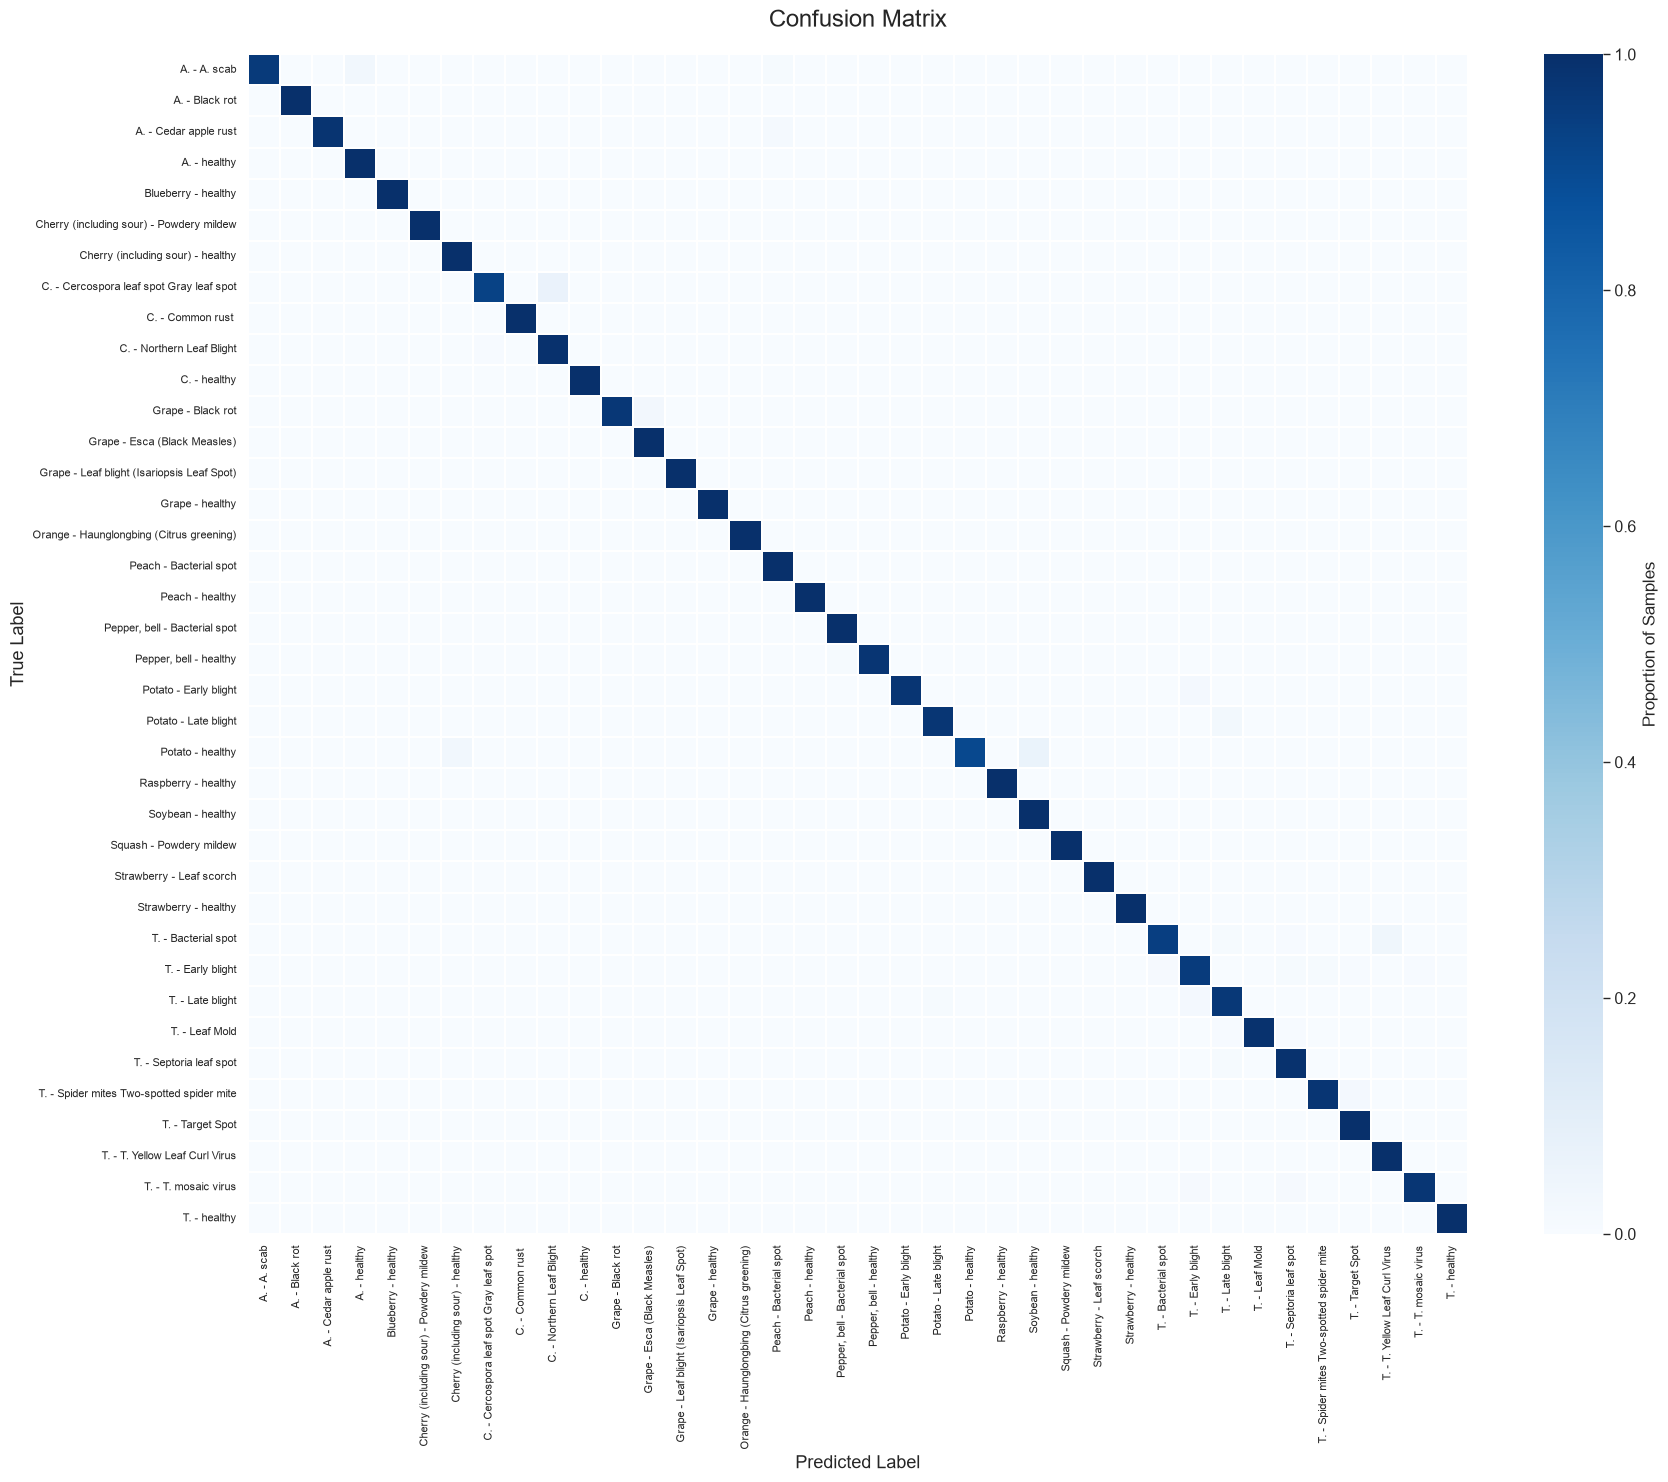

In [6]:
# Shorten class names
short_labels = [
    name.replace("___", " - ")
        .replace("_", " ")
        .replace("Tomato ", "T. ")
        .replace("Apple ", "A. ")
        .replace("Corn (maize) ", "C. ")
    for name in str_labels
]

fig, ax = plt.subplots(figsize=(18, 15))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=short_labels,
    yticklabels=short_labels,
    cbar_kws={"label": "Proportion of Samples"},
    linewidths=0.1,
    ax=ax
)

ax.set_xlabel("Predicted Label", fontsize=13)
ax.set_ylabel("True Label", fontsize=13)
ax.set_title("Confusion Matrix", fontsize=17, pad=20)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

The normalized confusion matrix illustrates the model's classification performance across all 38 plant disease classes. Each row represents the proportion of predictions for a given true class. The strong diagonal indicates high classification accuracy across most classes, while off-diagonal values highlight occasional misclassifications between diseases.

## 2.2 Classes with Zero Misclassifications

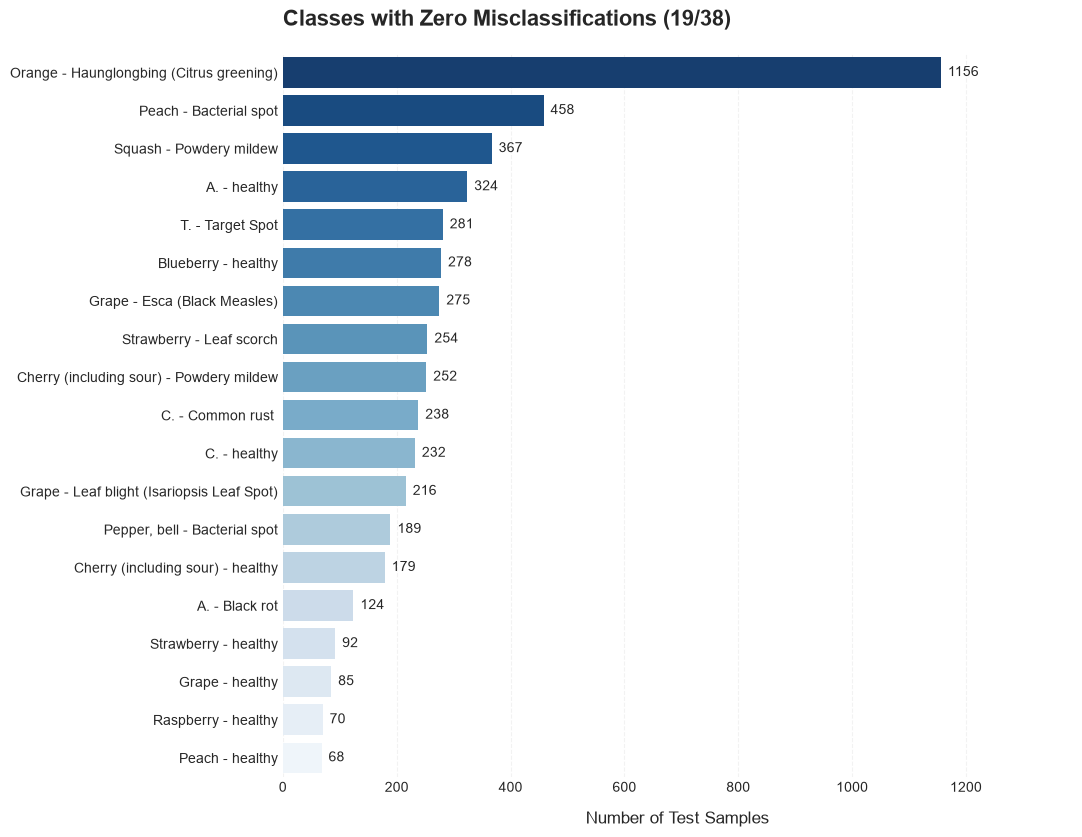

In [7]:
# Identify classes with zero misclassifications
perfect_idx = np.where(
    (error_counts == 0) & (class_sizes > 0)
)[0]

df_perfect = pd.DataFrame({
    "Class": np.array(short_labels)[perfect_idx],
    "Samples": class_sizes[perfect_idx]
}).sort_values("Samples", ascending=False)

plot_horizontal_bars(
    data=df_perfect,
    x="Samples",
    title=f"Classes with Zero Misclassifications ({len(df_perfect)}/{len(numeric_labels)})",
    xlabel="Number of Test Samples",
    figsize=(11, max(5, len(df_perfect) * 0.45)),
    value_format="%.0f",
    xlim=(0, max(df_perfect["Samples"].max() * 1.2, 1))
)

This chart highlights disease classes for which all test images were correctly classified (100% recall). The bar lengths represent the number of test samples per class, providing context for these results. Perfect recall on the test set does not necessarily imply perfect precision or generalization to unseen data.

## 2.3 Top-10 highest misclassification rates

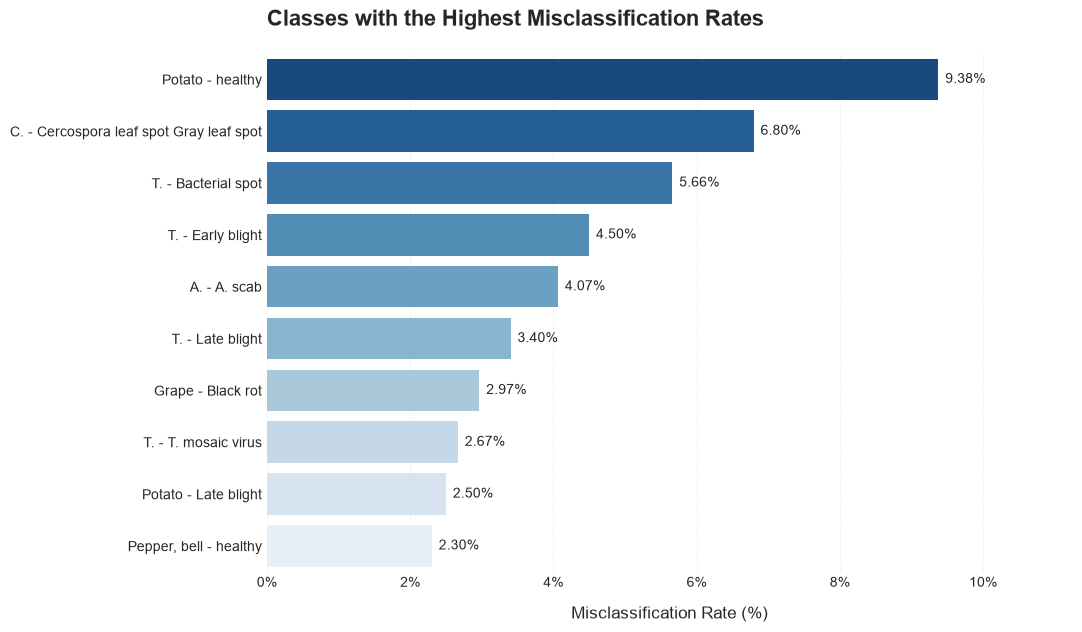

In [8]:
df_errors = pd.DataFrame({
    "Class": short_labels,
    "Error Rate (%)": error_rates_pct
})

df_errors = (
    df_errors
    .sort_values("Error Rate (%)", ascending=False)
    .head(10)
)

plot_horizontal_bars(
    data=df_errors,
    x="Error Rate (%)",
    title="Classes with the Highest Misclassification Rates",
    xlabel="Misclassification Rate (%)",
    value_format="%.2f%%",
    percentage_axis=True,
    xlim=(0, df_errors["Error Rate (%)"].max() * 1.2)
)

This chart identifies the ten disease classes with the highest misclassification rates, calculated relative to the total number of test samples in each class. It highlights where the model performs least reliably and helps prioritize classes for further investigation.

## 2.4 Class Size vs. Misclassification Rate

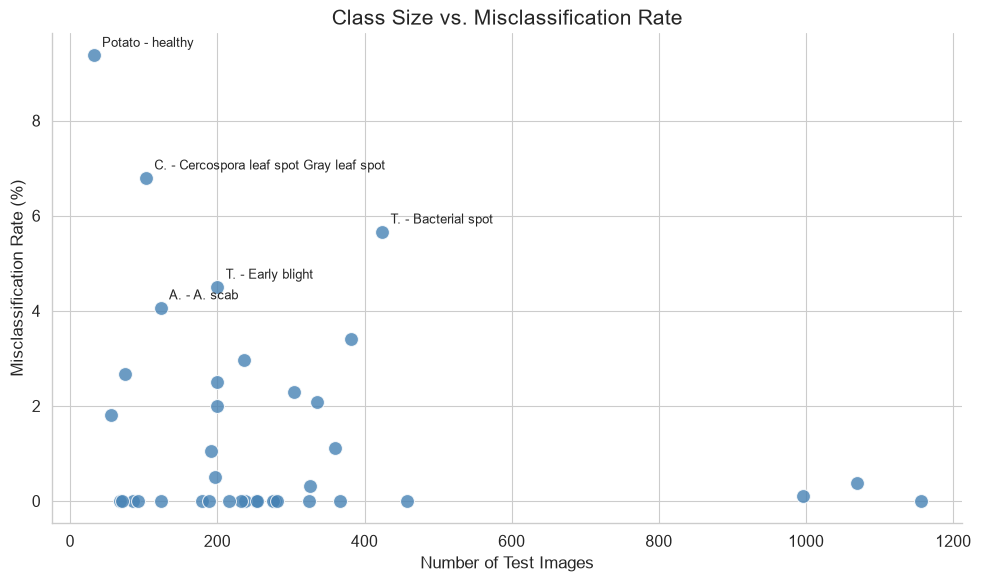

In [9]:
df_scatter = pd.DataFrame({
    "Class": short_labels,
    "Class Size": class_sizes,
    "Error Rate (%)": error_rates_pct
})

fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=df_scatter,
    x="Class Size",
    y="Error Rate (%)",
    s=100,
    alpha=0.8,
    color="steelblue",
    ax=ax
)

# Highlight the 5 worst-performing classes
for _, row in df_scatter.nlargest(5, "Error Rate (%)").iterrows():
    ax.annotate(
        row["Class"],
        (row["Class Size"], row["Error Rate (%)"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title("Class Size vs. Misclassification Rate", fontsize=15)
ax.set_xlabel("Number of Test Images")
ax.set_ylabel("Misclassification Rate (%)")

sns.despine()
plt.tight_layout()
plt.show()

This scatterplot explores the relationship between test class size and misclassification rate. Each point represents a disease class, with the five highest-error classes labeled for emphasis. The visualization helps assess whether observed error rates are associated with class size, although test set size alone does not explain classification difficulty.

# 3. Model Robustness Experiments

## 3.1 Lighting, Blur and Noise

In [10]:
# Configuration
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 38

In [11]:
# Load the original test split
dataset = load_dataset("geraldmc/plantvillage-full")
test_dataset = dataset["train"].filter(
    lambda sample: sample["split"] == "test"
)

# Reproduce original evaluation preprocessing
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [12]:
# Evaluate original test images
baseline = evaluate(
    model=model,
    dataset=test_dataset,
    device=device,
    transform=eval_transform,
    batch_size=BATCH_SIZE
)

print(f"Baseline accuracy: {baseline['accuracy']:.2f}%")

# Verify against the saved predictions
csv_accuracy = (
    df["true_idx"].to_numpy() ==
    df["pred_idx"].to_numpy()
).mean() * 100

print(f"CSV accuracy: {csv_accuracy:.2f}%")

Evaluating:   0%|          | 0/343 [00:00<?, ?batch/s]

Baseline accuracy: 99.02%
CSV accuracy: 99.02%


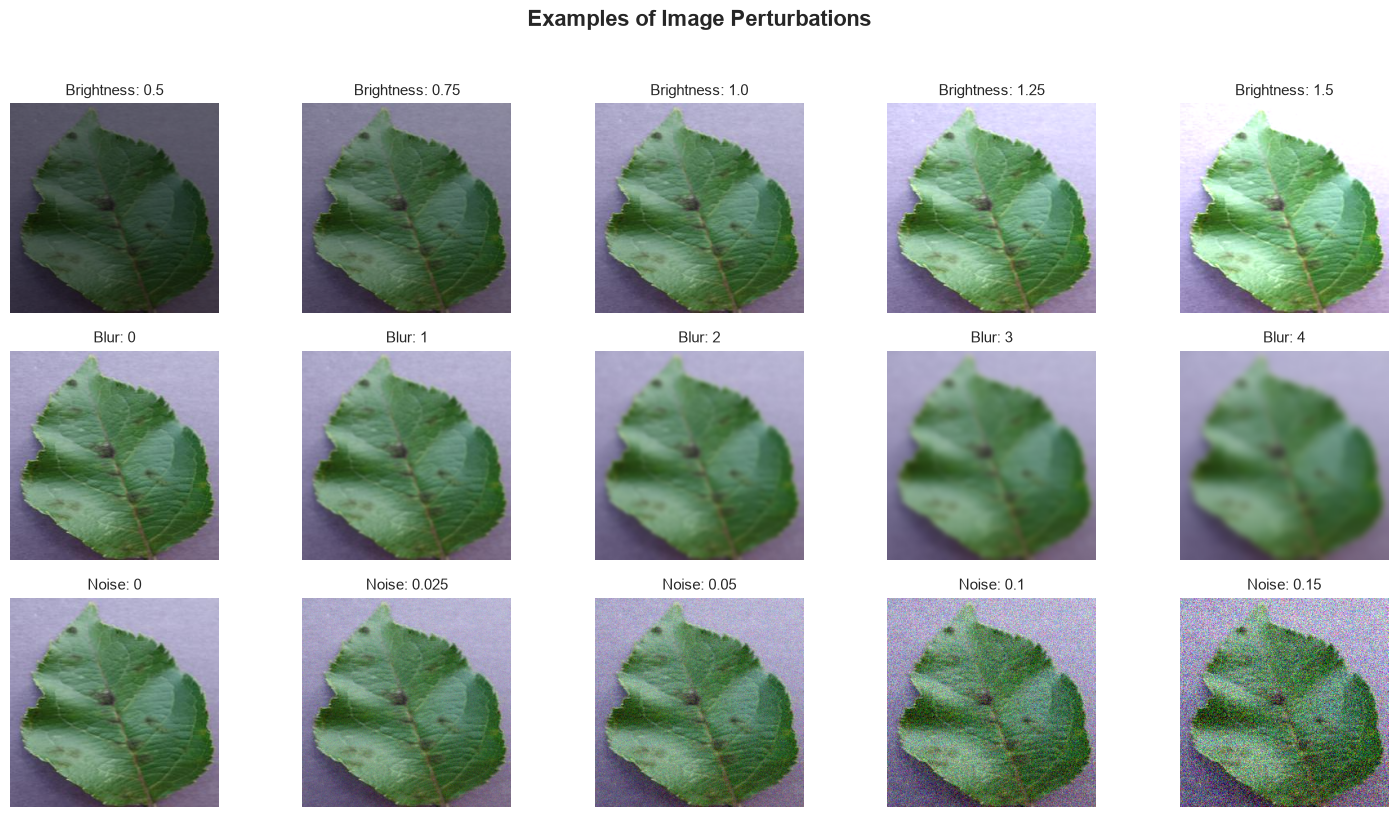

In [13]:
perturbations = {
    "Brightness": [0.5, 0.75, 1.0, 1.25, 1.5],
    "Blur": [0, 1, 2, 3, 4],
    "Noise": [0, 0.025, 0.05, 0.10, 0.15]
}

sample = test_dataset[0]["image"].convert("RGB")

fig, axes = plt.subplots(3, 5, figsize=(15, 8))

for row, (kind, strengths) in enumerate(perturbations.items()):
    for col, strength in enumerate(strengths):
        modified = perturb_image(
            sample, 0, kind, strength, seed=SEED
        )

        axes[row, col].imshow(modified)
        axes[row, col].set_title(
            f"{kind}: {strength}", fontsize=11
        )
        axes[row, col].axis("off")

fig.suptitle(
    "Examples of Image Perturbations",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

In [14]:
RUN_EXPERIMENTS = False
results_path = Path("outputs/resnet18/robustness_results.pkl")

if RUN_EXPERIMENTS:
    robustness_results = []
    robustness_predictions = {}

    for kind, strengths in perturbations.items():
        for strength in strengths:
            repetitions = 3 if kind == "Noise" and strength > 0 else 1

            for repetition in range(repetitions):
                transform = (
                    lambda image, idx, k=kind, s=strength, r=repetition:
                    perturb_image(image, idx, k, s, r, seed=SEED)
                )

                result = evaluate(
                    model=model,
                    dataset=test_dataset,
                    device=device,
                    transform=eval_transform,
                    image_transform=transform,
                    batch_size=BATCH_SIZE,
                    description=f"{kind} {strength:.3f} (Run {repetition + 1})"
                )

                robustness_results.append({
                    "Perturbation": kind,
                    "Strength": strength,
                    "Repetition": repetition,
                    "Accuracy (%)": result["accuracy"]
                })

                robustness_predictions[(kind, strength, repetition)] = result

                print(
                    f"{kind:10s} | "
                    f"Strength: {strength:.3f} | "
                    f"Run: {repetition + 1} | "
                    f"Accuracy: {result['accuracy']:.2f}%"
                )

    df_robustness = pd.DataFrame(robustness_results)

    # Save results
    results_path.parent.mkdir(parents=True, exist_ok=True)

    with open(results_path, "wb") as f:
        pickle.dump({
            "df_robustness": df_robustness,
            "robustness_predictions": robustness_predictions
        }, f)

    print(f"Results saved to {results_path}")

else:
    # Load previous results
    if not results_path.exists():
        raise FileNotFoundError(
            f"No cached results at {results_path}. "
            "Set RUN_EXPERIMENTS = True first."
        )

    with open(results_path, "rb") as f:
        saved = pickle.load(f)

    df_robustness = saved["df_robustness"]
    robustness_predictions = saved["robustness_predictions"]

    print(f"Results loaded from {results_path}")

Results loaded from outputs\resnet18\robustness_results.pkl


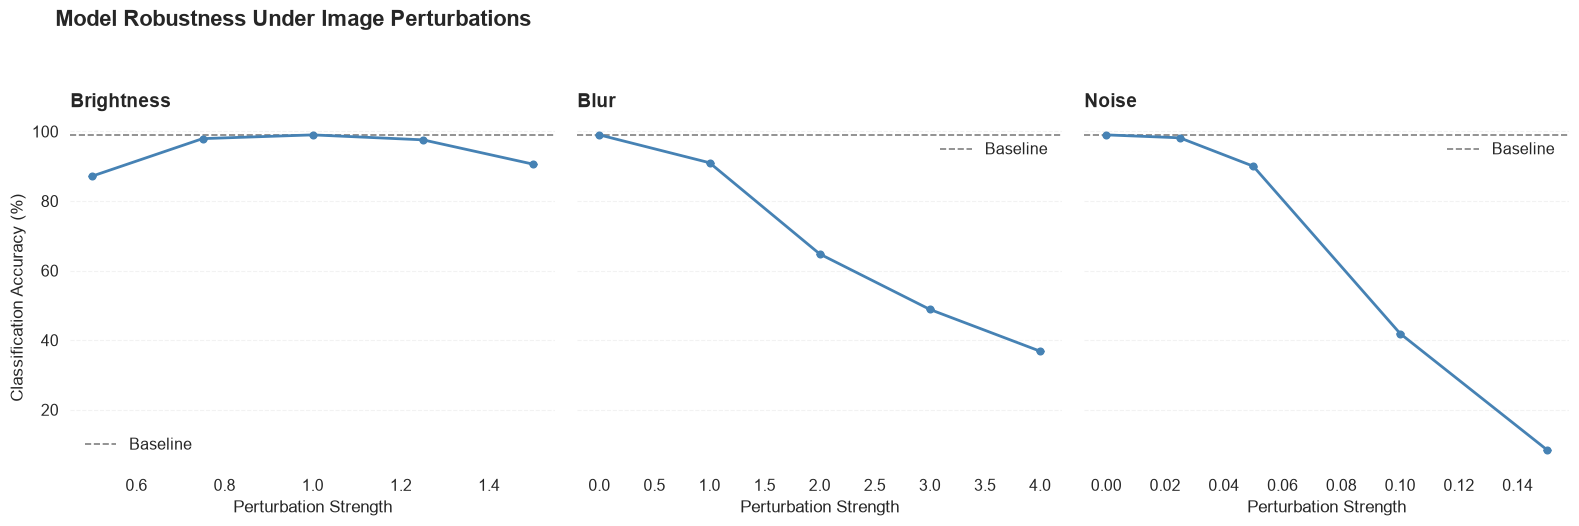

In [15]:
df_robustness_summary = (
    df_robustness
    .groupby(["Perturbation", "Strength"], as_index=False)
    .agg(
        accuracy_mean=("Accuracy (%)", "mean"),
        accuracy_std=("Accuracy (%)", "std")
    )
    .fillna({"accuracy_std": 0})
)

plot_robustness_curves(
    df_robustness_summary,
    perturbations,
    baseline["accuracy"]
)

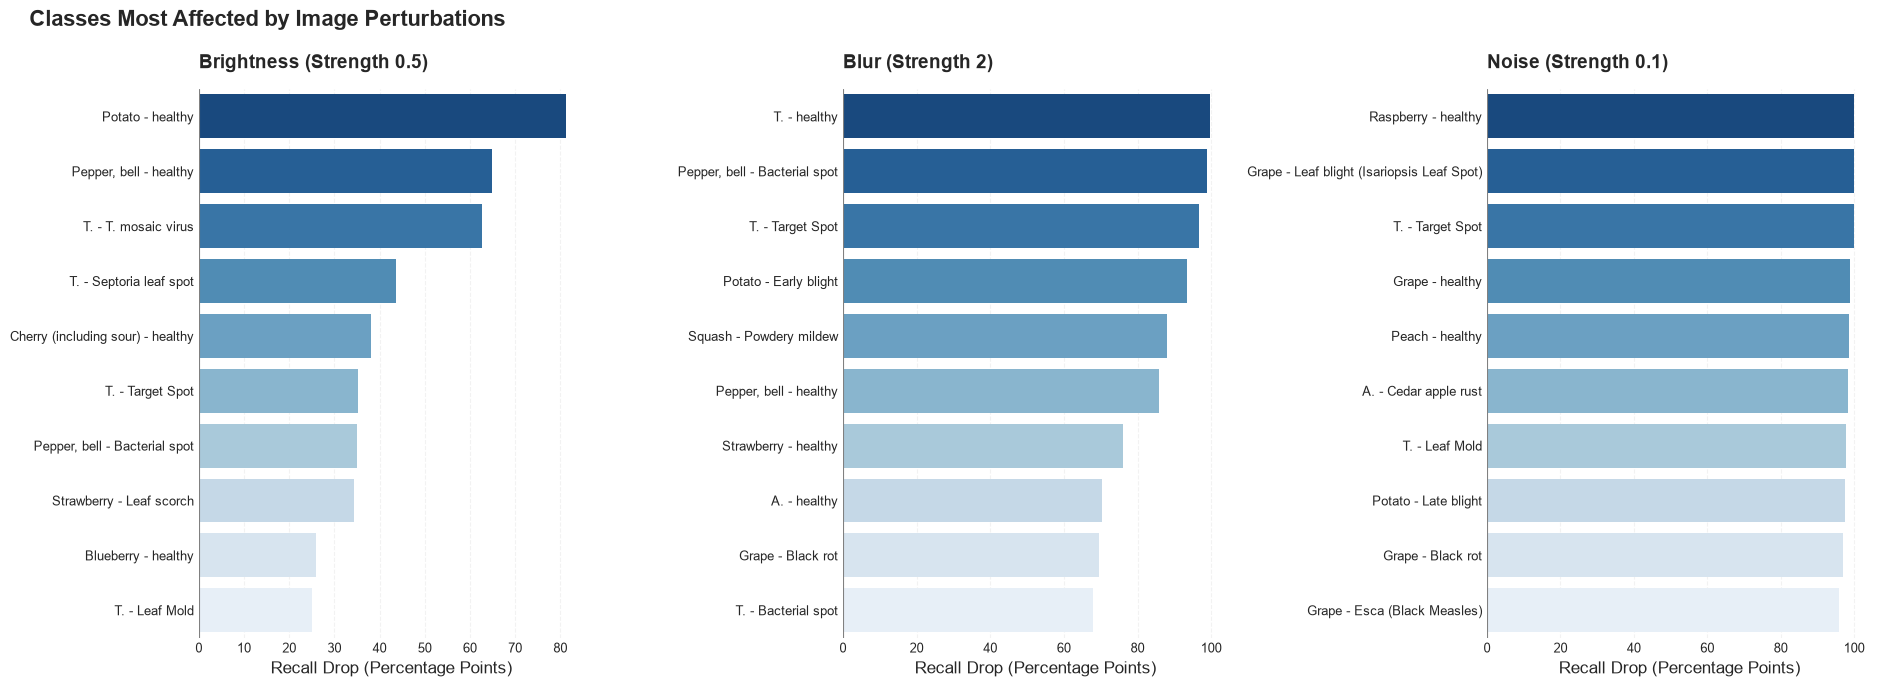

In [16]:
# Perturbation strengths to compare
selected_strengths = {
    "Brightness": 0.5,
    "Blur": 2,
    "Noise": 0.10
}

original_recall = class_recall(
    baseline["true"], baseline["pred"], NUM_CLASSES
)

sensitivity_results = {}

for kind, strength in selected_strengths.items():
    recalls = [
        class_recall(result["true"], result["pred"], NUM_CLASSES)
        for (k, s, repetition), result in robustness_predictions.items()
        if k == kind and np.isclose(s, strength)
    ]

    if not recalls:
        raise ValueError(f"No predictions found for {kind} {strength}")

    modified_recall = np.nanmean(recalls, axis=0)

    df_sensitive = pd.DataFrame({
        "Class": short_labels,
        "Original Recall (%)": original_recall,
        "Modified Recall (%)": modified_recall
    })

    df_sensitive["Recall Drop (pp)"] = (
        df_sensitive["Original Recall (%)"]
        - df_sensitive["Modified Recall (%)"]
    )

    sensitivity_results[kind] = (
        df_sensitive
        .sort_values("Recall Drop (pp)", ascending=False)
        .head(10)
    )

plot_class_sensitivity(sensitivity_results, selected_strengths)

## 3.2 Foreground vs. Background

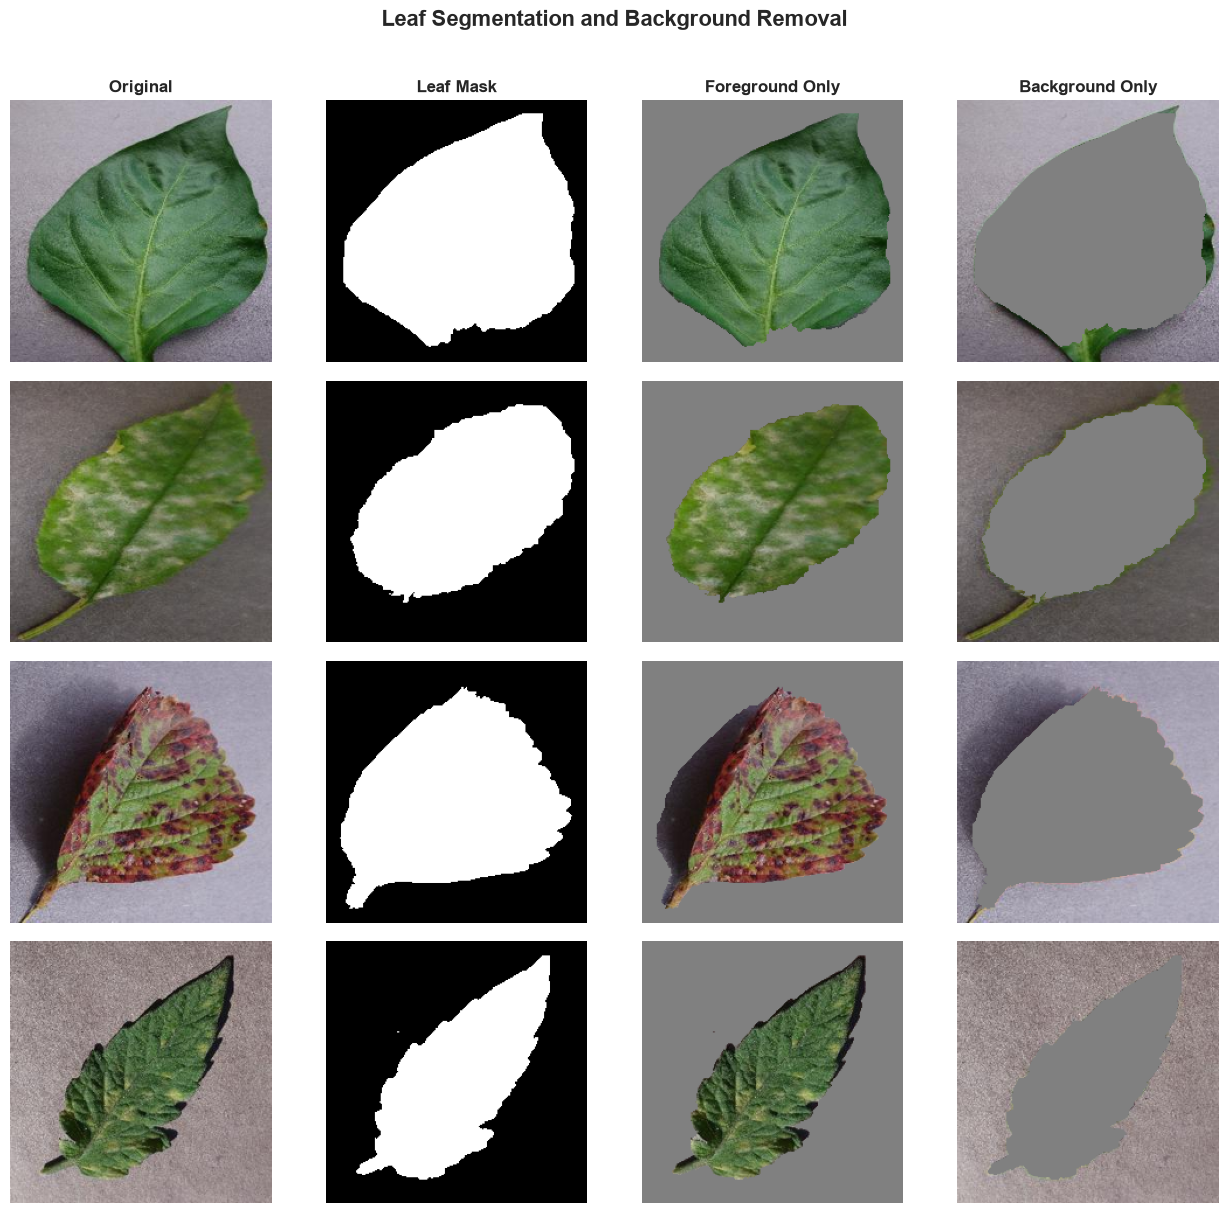

In [17]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(
    len(test_dataset), size=min(4, len(test_dataset)), replace=False
)

plot_segmentation_examples(test_dataset, sample_indices, IMAGE_SIZE, SEED)

In [18]:
RUN_REGION_EXPERIMENTS = False
regions_path = Path("outputs/resnet18/region_results.pkl")

if RUN_REGION_EXPERIMENTS:
    region_results = {}

    for mode in ["foreground", "background"]:
        region_results[mode] = evaluate(
            model=model,
            dataset=test_dataset,
            device=device,
            transform=eval_transform,
            image_transform=lambda image, idx, m=mode: region_transform(
                image, idx, m, test_dataset, IMAGE_SIZE, SEED
            ),
            batch_size=BATCH_SIZE,
            description=f"Evaluating {mode}"
        )

    foreground_result = region_results["foreground"]
    background_result = region_results["background"]

    regions_path.parent.mkdir(parents=True, exist_ok=True)

    with open(regions_path, "wb") as f:
        pickle.dump(region_results, f)

else:
    if not regions_path.exists():
        raise FileNotFoundError(
            f"No cached results at {regions_path}. "
            "Set RUN_REGION_EXPERIMENTS = True first."
        )

    with open(regions_path, "rb") as f:
        region_results = pickle.load(f)

    foreground_result = region_results["foreground"]
    background_result = region_results["background"]

print(f"Original:        {baseline['accuracy']:.2f}%")
print(f"Foreground only: {foreground_result['accuracy']:.2f}%")
print(f"Background only: {background_result['accuracy']:.2f}%")

Original:        99.02%
Foreground only: 80.15%
Background only: 35.55%


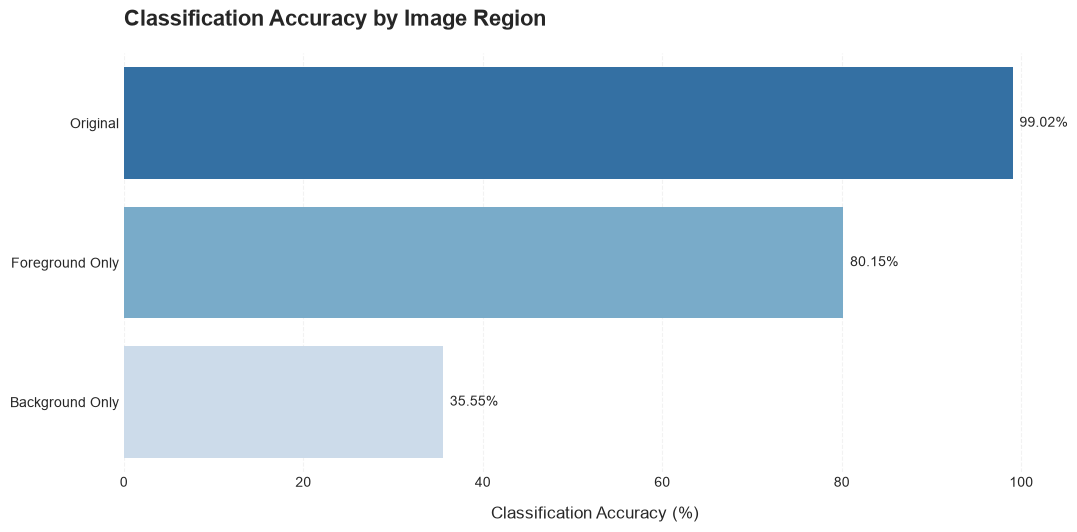

In [19]:
df_regions = pd.DataFrame({
    "Input": ["Original", "Foreground Only", "Background Only"],
    "Accuracy (%)": [
        baseline["accuracy"],
        foreground_result["accuracy"],
        background_result["accuracy"]
    ]
})

plot_horizontal_bars(
    data=df_regions,
    x="Accuracy (%)",
    y="Input",
    title="Classification Accuracy by Image Region",
    xlabel="Classification Accuracy (%)",
    figsize=(11, 5.5),
    value_format="%.2f%%",
    xlim=(0, 105)
)

In [20]:
df_changes = pd.DataFrame({
    "True": baseline["true"],
    "Original": baseline["pred"],
    "Foreground": foreground_result["pred"],
    "Background": background_result["pred"]
})

original_correct = df_changes["Original"] == df_changes["True"]

for mode in ["Foreground", "Background"]:
    changed = (df_changes["Original"] != df_changes[mode]).mean() * 100
    new_errors = (
        original_correct &
        (df_changes[mode] != df_changes["True"])
    ).sum()

    print(f"{mode}: {changed:.2f}% changed predictions, {new_errors} new errors")

Foreground: 19.73% changed predictions, 2092 new errors
Background: 64.41% changed predictions, 6962 new errors


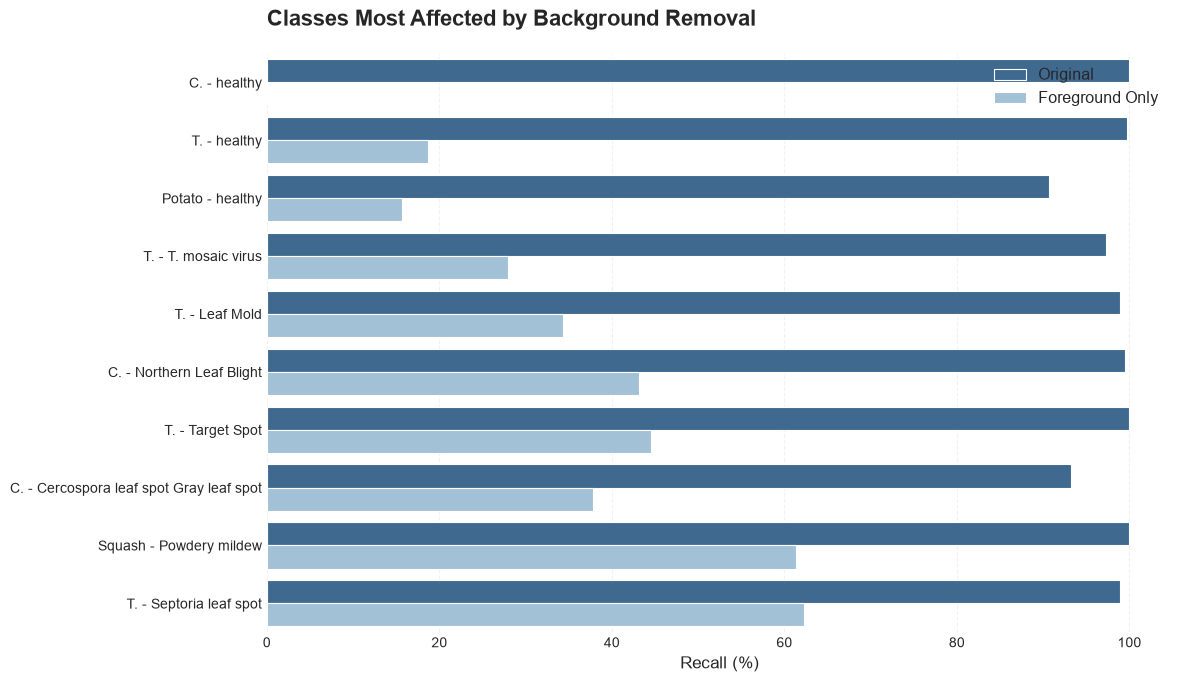

In [21]:
df_region_recall = pd.DataFrame({
    "Class": short_labels,
    "Original": class_recall(
        baseline["true"], baseline["pred"], NUM_CLASSES
    ),
    "Foreground Only": class_recall(
        foreground_result["true"], foreground_result["pred"], NUM_CLASSES
    ),
    "Background Only": class_recall(
        background_result["true"], background_result["pred"], NUM_CLASSES
    )
})

df_region_recall["Recall Drop (pp)"] = (
    df_region_recall["Original"] - df_region_recall["Foreground Only"]
)

df_top = (
    df_region_recall
    .sort_values("Recall Drop (pp)", ascending=False)
    .head(10)
)

plot_region_recall(df_top)